# 04 · Topology of the tree and clustering

* **Degree:** the number of direct neighbours. High-degree vertices are local hubs.
* **Betweenness centrality:** the share of all shortest paths passing through a vertex.
  In a tree there is exactly one path between any two vertices, so this measures how much
  of the market "flows through" a share.
* **Closeness centrality:** the inverse mean distance to all other vertices along the
  tree, with distances measured in $d_{ij}$.
* **Eccentricity:** the distance to the farthest vertex. The vertex with the smallest
  eccentricity is the centre of the tree.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

from moex_network import config, correlation, data, metrics, mst, plotting

plotting.use_style()
pd.set_option("display.precision", 3)

In [2]:
dist = pd.read_csv(config.DISTANCE_MATRIX, index_col=0)
corr = pd.read_csv(config.CORRELATION_MATRIX, index_col=0)
prices = data.load_prices(config.CLEAN_PRICES)
tree = mst.build_mst(dist)

node_metrics = metrics.node_metrics(tree)
node_metrics.to_csv(config.NODE_METRICS)
node_metrics.head(12)

,sector,degree,betweenness,closeness,eccentricity
ticker,,,,,
MAGN,Metals & Mining,7,0.705,0.410,5.031
ALRS,Metals & Mining,5,0.678,0.410,4.186
ROSN,Oil & Gas,5,0.220,0.280,5.933
NLMK,Metals & Mining,4,0.178,0.285,6.424
SMLT,Real Estate,4,0.178,0.314,5.966
FLOT,Transport,4,0.136,0.307,6.010
NVTK,Oil & Gas,3,0.359,0.341,5.075
SBER,Financials,3,0.092,0.308,5.101
GAZP,Oil & Gas,3,0.092,0.275,5.862


In [3]:
summary = metrics.tree_summary(tree)
pd.Series(summary, name="value").to_frame()

,value
nodes,44
edges,43
total_length,41.203
mean_edge_rho,0.535
diameter,8.321
diameter_hops,9
radius,4.186
avg_path_length,4.112
avg_path_hops,4.501
center,[ALRS]


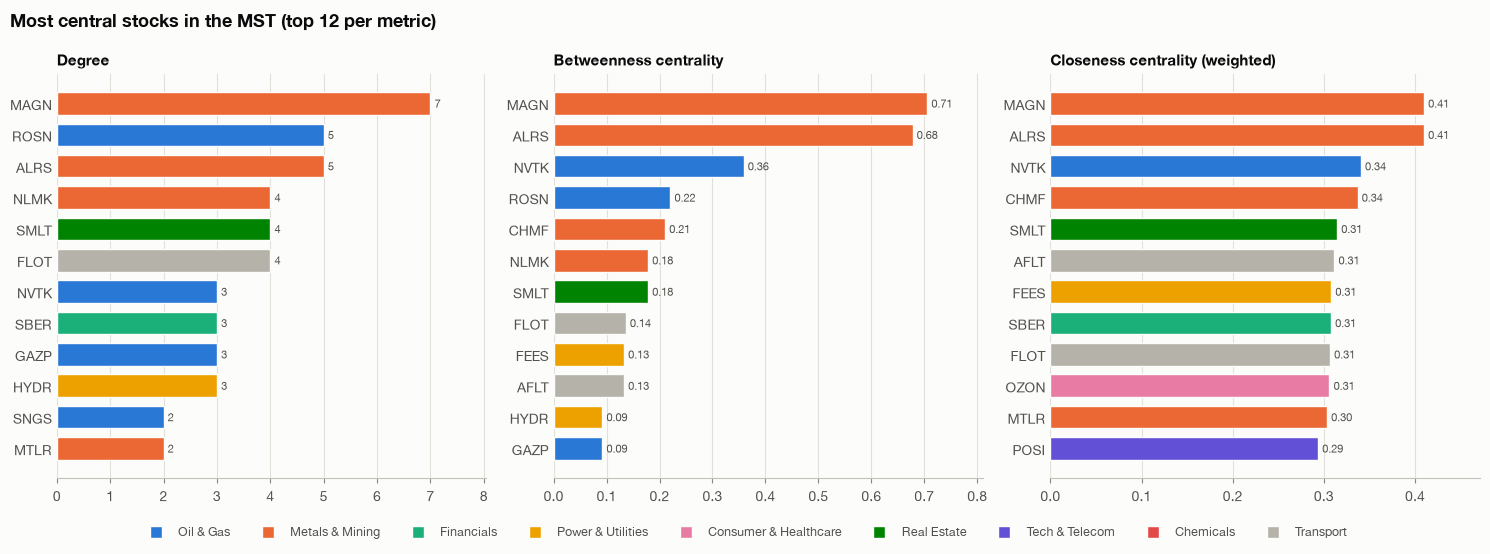

In [4]:
plotting.plot_centrality(node_metrics, top=12,
                         path=config.FIGURES_DIR / "centrality.png");

## Hubs and leaves

In [5]:
roles = metrics.classify_nodes(node_metrics)
print("Hubs (degree ≥ mean + 1σ and betweenness ≥ mean):")
display(node_metrics.loc[roles["hubs"]])
print(f"Leaves (degree 1): {len(roles['leaves'])} of {len(node_metrics)}")
print(", ".join(roles["leaves"]))

Hubs (degree ≥ mean + 1σ and betweenness ≥ mean):


,sector,degree,betweenness,closeness,eccentricity
ticker,,,,,
MAGN,Metals & Mining,7,0.705,0.410,5.031
ALRS,Metals & Mining,5,0.678,0.410,4.186
ROSN,Oil & Gas,5,0.220,0.280,5.933
NLMK,Metals & Mining,4,0.178,0.285,6.424
SMLT,Real Estate,4,0.178,0.314,5.966
FLOT,Transport,4,0.136,0.307,6.010


Leaves (degree 1): 23 of 44
VTBR, CBOM, RENI, LKOH, TATN, SIBN, GMKN, PLZL, FESH, MGNT, BELU, ABRD, MTSS, POSI, WUSH, WTCM, AKRN, IRAO, MSNG, PIKK, LSRG, RASP, MDMG


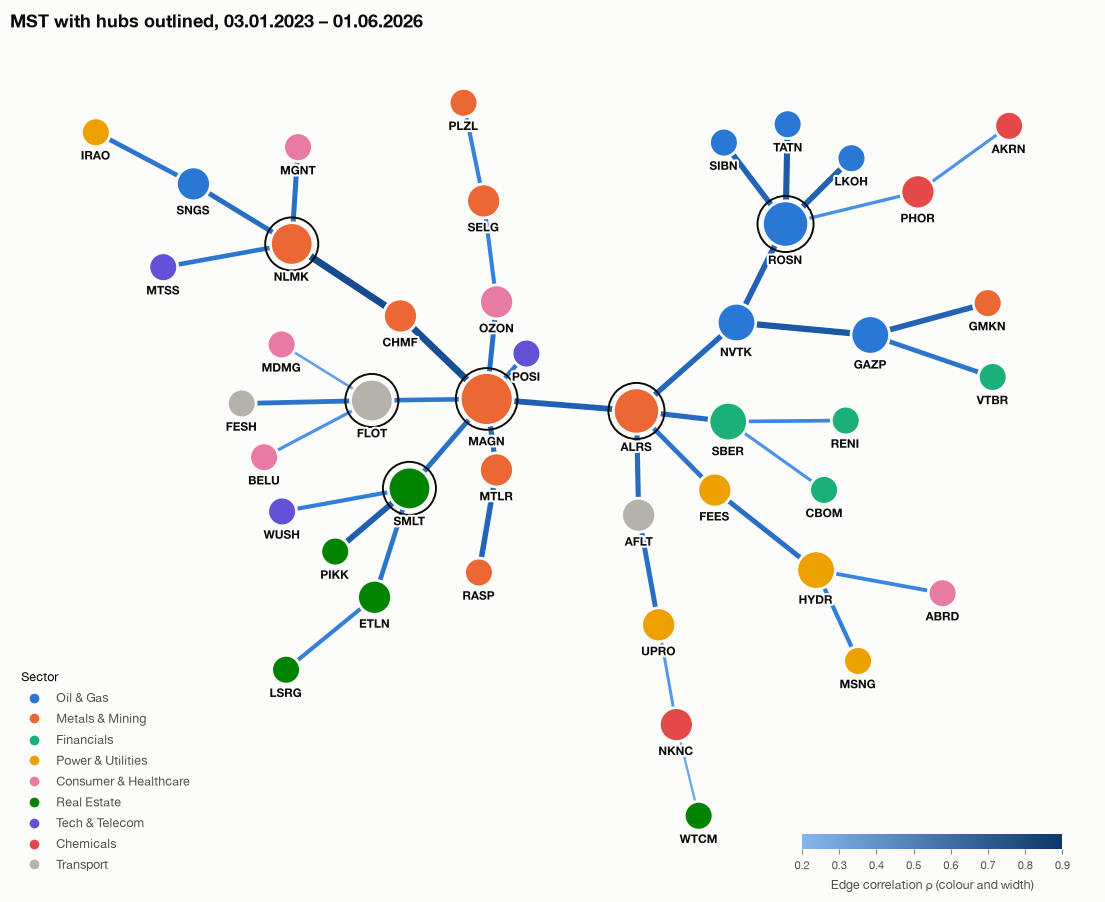

In [6]:
period = f"{prices.index[0]:%d.%m.%Y} – {prices.index[-1]:%d.%m.%Y}"
plotting.plot_mst(tree, f"MST with hubs outlined, {period}", highlight=roles["hubs"],
                  path=config.FIGURES_DIR / "mst_hubs.png");

## Sector structure

Does the tree recover the economic sectors? Each edge is labelled as intra-sector or
inter-sector.

In [7]:
edges = metrics.sector_edge_stats(tree)
print(f"intra-sector edges: {edges['intra'].sum()} of {len(edges)} ({edges['intra'].mean():.0%})")

intra-sector edges: 20 of 43 (47%)


In [8]:
# Baseline: share of intra-sector edges if the 43 edges were drawn at random.
import numpy as np
sizes = pd.Series(config.SECTOR_OF).value_counts()
n = sizes.sum()
p_random = (sizes * (sizes - 1)).sum() / (n * (n - 1))
print(f"expected under random pairing: {p_random:.0%}")

expected under random pairing: 11%


In [9]:
edges.loc[~edges["intra"]]

,u,v,sector_u,sector_v,rho,intra
8,GAZP,GMKN,Oil & Gas,Metals & Mining,0.629,False
11,NVTK,ALRS,Oil & Gas,Metals & Mining,0.605,False
12,SBER,ALRS,Financials,Metals & Mining,0.581,False
13,ALRS,AFLT,Metals & Mining,Transport,0.577,False
15,SNGS,NLMK,Oil & Gas,Metals & Mining,0.567,False
16,NLMK,MGNT,Metals & Mining,Consumer & Healthcare,0.564,False
17,MAGN,OZON,Metals & Mining,Consumer & Healthcare,0.563,False
18,MAGN,SMLT,Metals & Mining,Real Estate,0.562,False
20,UPRO,AFLT,Power & Utilities,Transport,0.559,False
22,VTBR,GAZP,Financials,Oil & Gas,0.538,False


## Hierarchical clustering

Single-linkage clustering on $d_{ij}$ is mathematically equivalent to the MST. Cutting the
tree at a distance threshold gives the same clusters as cutting the dendrogram at that
height. The dendrogram shows at which correlation level each group merges.

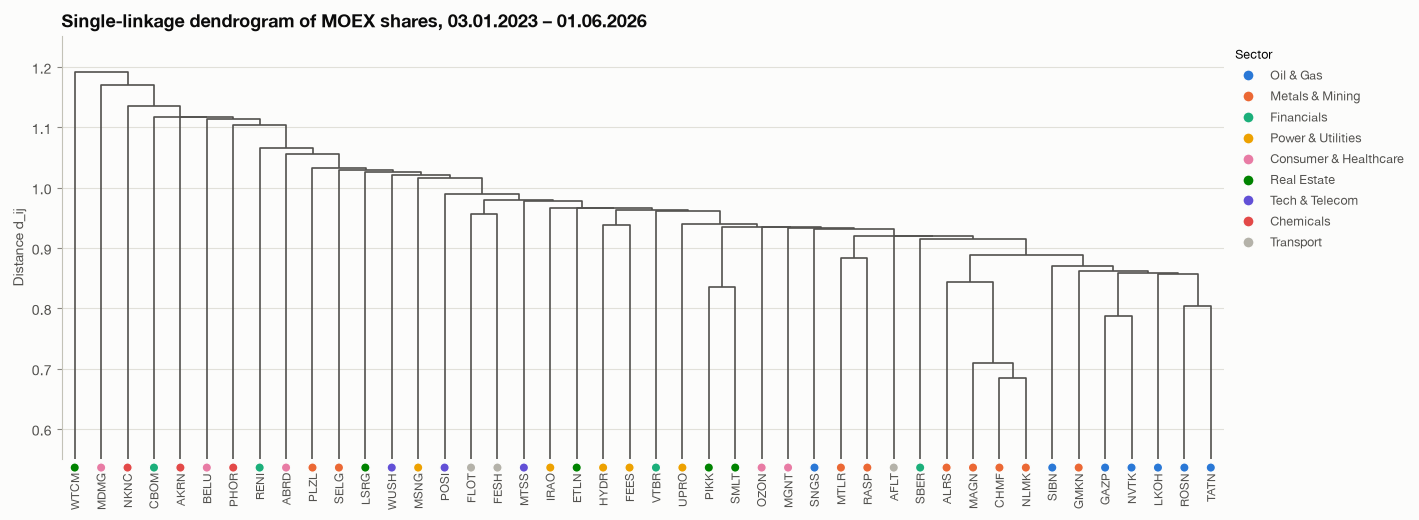

In [10]:
plotting.plot_dendrogram(dist, f"Single-linkage dendrogram of MOEX shares, {period}",
                         path=config.FIGURES_DIR / "dendrogram.png");

In [11]:
# Clusters = connected components after removing MST edges with ρ < threshold
import networkx as nx

def clusters_at(tree, rho_min):
    strong = nx.Graph()
    strong.add_nodes_from(tree)
    strong.add_edges_from((u, v) for u, v, d in tree.edges(data=True) if d["rho"] >= rho_min)
    comps = [sorted(c) for c in nx.connected_components(strong) if len(c) > 1]
    return sorted(comps, key=len, reverse=True)

for rho_min in (0.55, 0.60, 0.62):
    print(f"ρ ≥ {rho_min:.2f}")
    for c in clusters_at(tree, rho_min):
        print(f"   {len(c):2d}  {', '.join(c)}")

ρ ≥ 0.55
   21  AFLT, ALRS, CHMF, GAZP, GMKN, LKOH, MAGN, MGNT, MTLR, NLMK, NVTK, OZON, PIKK, RASP, ROSN, SBER, SIBN, SMLT, SNGS, TATN, UPRO
    2  FEES, HYDR
ρ ≥ 0.60
   11  ALRS, CHMF, GAZP, GMKN, LKOH, MAGN, NLMK, NVTK, ROSN, SIBN, TATN
    2  PIKK, SMLT
    2  MTLR, RASP
ρ ≥ 0.62
    7  GAZP, GMKN, LKOH, NVTK, ROSN, SIBN, TATN
    4  ALRS, CHMF, MAGN, NLMK
    2  PIKK, SMLT


At ρ ≥ 0.55 a single core of 21 stocks holds together: this is the market mode. Raising
the threshold to 0.62 splits it into three clear sector clusters: **oil & gas** (plus
GMKN), **steel & diamonds** (CHMF, NLMK, MAGN, ALRS) and **developers** (PIKK, SMLT).

## Interpretation

**1. A strong market mode.** All 946 pairwise correlations are positive (min 0.11,
mean 0.39). Over 2023–2026 most Russian shares moved with a common factor, so
diversifying only *within* MOEX equities has clear limits.

**2. The tree recovers the sectors.** 47 % of MST edges connect two shares from the same
sector. If 43 edges were drawn at random, only 11 % would. Oil & gas is the most cohesive
sector: its stocks correlate at 0.58 with each other and at 0.41 with the rest of the
market. The steel trio CHMF–NLMK–MAGN gives the three strongest pairs of the whole
market (ρ = 0.74–0.77).

**3. Metals & mining form the backbone.** MAGN (degree 7, betweenness 0.71) and ALRS
(betweenness 0.68, the centre of the tree) sit on the main trunk. The MAGN–ALRS edge
roughly separates two parts of the market: oil & gas, financials and power on one side; steel,
real estate, transport and consumer names on the other. Together with ROSN, NLMK, SMLT
and FLOT they meet the hub criterion.

**4. Financials do not form a block.** SBER links to ALRS and is the local parent of
CBOM and RENI. VTBR attaches to GAZP rather than to SBER. Average within-sector
correlation (0.37) is the same as the sector's correlation with the market.

**5. The periphery is made of idiosyncratic names.** WTCM, NKNC, MDMG, AKRN and BELU
connect to the tree through its weakest edges (ρ < 0.4). Chemicals barely co-move even
with each other (0.27 inside the sector). IRAO and WTCM are the two ends of the tree's
diameter.

**6. Why the split adjustment matters.** Without it, PLZL hangs off MAGN and looks
"uncorrelated with the market" (mean ρ 0.10), which could be misread as a defensive
asset. After the adjustment it sits next to SELG (both gold miners), and its mean ρ rises
to 0.29. VTBR, GMKN and BELU show the same effect (notebook 01).

**Portfolio takeaway.** Shares from distant branches of the tree (e.g. oil & gas vs.
developers vs. chemicals) give more diversification than shares from the same branch.
Hubs such as MAGN and ALRS carry the most market-wide exposure.